In [1]:
%%capture output
import numpy as np
import pandas as pd
import glob
import os
import imageio
import matplotlib.pyplot as plt
from PIL import Image
import random
import skimage
import cv2
from math import radians, cos, sin
import math
import SimpleITK as sitk
import gui
import registration_gui as rgui
from cellpose import models
from tqdm import trange
import copy

In [2]:
%matplotlib widget

## Set Parameters

In [3]:
canvas_size = 2000 # in µm
mic_spacing = 0.325 # in µm 10X ~ 0.65; 20X ~ 0.325; 50X ~ 0.13
ms_spacing = 1 # in µm
cell_density = 0.1 # percentage of total canvas area
rotation = -0 # in degree
scale = 1.0 
mass_list = [577.5, 760.68]
diffusion = 0 # in µm
noise_loc = 0.0 # mean of noise level; default 0.1
noise_scale = 0.0 # spread of noise level; default 0.2
manual_registration = False # choose to perform the initial landmark registration by hand or use predefined parameters
seed = 0

In [4]:
path_sample_cells = "D:/Jan/fiscas-validationKit/Cell_images/microscopy/"

## Function Definitions

In [5]:
# loads random cell images and their corresponding masks from folder with prepared cell images and applies random rotation and scale
# returns randomized cell image with its corresponding mask
def load_random_cell(mask_index=255, seed=None):
    if seed is None:
        cell_chosen = random.randint(0, len(cell_image_paths)-1)
        angle = random.randint(0, 360)
        scaling_factor = random.uniform(0.8, 1.2)
    else:
        cell_chosen = seed
        angle = 0
        scaling_factor = 1
    cell_mask = np.array(Image.open(cell_masks_paths[cell_chosen]))
    cell_mask[cell_mask > 0] = mask_index
    with Image.open(cell_image_paths[cell_chosen]) as img:
        cell_image = np.zeros((img.size[1], img.size[0], img.n_frames))
        for i in range(img.n_frames):
            img.seek(i)
            cell_image[:, :, i] = skimage.exposure.equalize_adapthist(np.array(img))
    cell_rotated = skimage.transform.rotate(cell_image, angle, resize=True)
    mask_rotated = skimage.transform.rotate(np.array(cell_mask), angle, order=0, resize=True)
    cell_scaled = skimage.transform.rescale(cell_rotated, scaling_factor, anti_aliasing=True)
    mask_scaled = skimage.transform.rescale(mask_rotated, scaling_factor, order=0, anti_aliasing=False)
    cell_scaled[mask_scaled == 0] = 0
    return cell_scaled, mask_scaled.astype(np.uint16)


# apply diffusion on cell mask
def diffuse_mask(mask, diffusion):
    mask[mask > 0] = 255
    r = int(diffusion / ms_spacing)
    if r < 1:
        return mask
    kernel = np.fromfunction(lambda x, y: ((x-r)**2 + (y-r)**2 <= r**2)*1, (2*r+1, 2*r+1), dtype=int).astype(np.uint8)
    padding = r
    mask_padded = np.zeros((len(mask)+2*padding, len(mask[0])+2*padding))
    mask_padded[padding:padding+len(mask), padding:padding+len(mask[0])] = mask
    dil_sample = cv2.dilate(np.float32(mask_padded), kernel, iterations = 1)
    dil_sample = dil_sample.astype('uint8')
    dil_sample = dil_sample * 255
    return dil_sample


def generate_maldi_cell(mask, sigma=4.0, diffusion=0):
    mask = copy.deepcopy(mask)
    if diffusion != 0:
        mask = diffuse_mask(mask, diffusion)
    mask_scaled = skimage.transform.rescale(mask, (mic_spacing / ms_spacing), order=1)
    mask_bin = np.zeros_like(mask_scaled)
    mask_bin[mask_scaled > 0.7 * np.max(mask_scaled)]=1
    coords = np.argwhere(mask_bin > 0)
    center_of_mass = coords.mean(axis=0)
    cx, cy = center_of_mass
    intensities = np.zeros_like(mask_bin, dtype=float)
    for x, y in coords:
        distance = np.sqrt((x-cx)**2 + (y-cy)**2)
        intensities[x, y] = np.exp(-distance**2 / (2 * sigma**2)) + 0.1
    return intensities, np.sum(intensities)


def calculate_cell_density():
    total_area = mask_canvas.shape[0] * mask_canvas.shape[1]
    cell_area = np.count_nonzero(mask_canvas)
    density = cell_area / total_area
    return density


def decompose_affine_2d(matrix):
    u, s, vh = np.linalg.svd(matrix)
    rotation = np.dot(u, vh)
    scale = s
    shear_angle = np.arctan2(rotation[0, 1], rotation[0, 0])
    return rotation, scale, shear_angle


def calculate_rotation_angle(rotation_matrix):
    a, b = rotation_matrix[0]
    c, d = rotation_matrix[1]
    theta_rad = np.arctan2(c, a)
    theta_deg = np.degrees(theta_rad)
    return theta_rad, theta_deg


def interpret_registration_matrix(transformations):
    if isinstance(transformations, sitk.CompositeTransform):
        for i in range(transformations.GetNumberOfTransforms()):
            sub_transform = transformations.GetNthTransform(i)
            print(f"Transform {i}:")
            if isinstance(sub_transform, sitk.Euler2DTransform):
                matrix = np.reshape(sub_transform.GetMatrix(), (2,2))
                translation = sub_transform.GetTranslation()
                theta_rad, theta_deg = calculate_rotation_angle(matrix)
                print(f"Translation: {translation} \nRotation: {matrix} \n Rotation in deg: {theta_deg}")
            elif isinstance(sub_transform, sitk.AffineTransform):
                matrix = sub_transform.GetMatrix()
                translation = sub_transform.GetTranslation()
                print("Affine Transform Matrix:", matrix)
                print("Translation:", translation)
                rot, scale, shear = decompose_affine_2d(np.reshape(np.asarray(matrix), (2,2)))
                theta_rad, theta_deg = calculate_rotation_angle(rot)
                print(f"Translation: {translation} \nRotation: {rot} \n Rotation in deg: {theta_deg} \nScale: {scale} \nShear: {shear}")
            elif isinstance(sub_transform, sitk.TranslationTransform):
                translation = sub_transform.GetOffset()
                print("Translation Transform Offset:", translation)
            elif isinstance(sub_transform, sitk.Similarity2DTransform):
                matrix = np.reshape(sub_transform.GetMatrix(), (2,2))
                translation = sub_transform.GetTranslation()
                scale = sub_transform.GetScale()
                theta_rad, theta_deg = calculate_rotation_angle(matrix)
                print(f"Translation: {translation} \nRotation: {matrix} \n Rotation in deg: {theta_deg} \nScale: {scale}")
    else:
        if isinstance(transformations, sitk.AffineTransform):
            matrix = transformations.GetMatrix()
            translation = transformations.GetTranslation()
            print("Affine Transform Matrix:", matrix)
            print("Translation:", translation)
        elif isinstance(transformations, sitk.TranslationTransform):
            translation = transformations.GetOffset()
            print("Translation Transform Offset:", translation)
        elif isinstance(transformations, sitk.Similarity2DTransform):
            matrix = np.reshape(transformations.GetMatrix(), (2,2))
            translation = transformations.GetTranslation()
            scale = transformations.GetScale()
            theta_rad, theta_deg = calculate_rotation_angle(matrix)
            print(f"Translation: {translation} \nRotation: {matrix} \n Rotation in deg: {theta_deg} \nScale: {scale}")
    return None


def rotate_coordinates(coords, angle_deg, center_point):
    angle_rad = radians(angle_deg)
    rotation_matrix = np.array([
        [cos(angle_rad), -sin(angle_rad)],
        [sin(angle_rad), cos(angle_rad)]
    ])
    rotated_coords = []
    for x, y in coords:
        translated_coords = np.array([x - center_point[0], y - center_point[1]])
        rotated_translated_coords = np.dot(rotation_matrix, translated_coords)
        new_x, new_y = rotated_translated_coords + center_point
        rotated_coords.append((new_x, new_y))
    return rotated_coords


def scale_coordinates(coords, scale_factors, center_point):
    scaled_coords = []
    for x, y in coords:
        translated_coords = np.array([x - center_point[0], y - center_point[1]])
        scaled_translated_coords = translated_coords * np.array(scale_factors)
        new_x, new_y = scaled_translated_coords + center_point
        scaled_coords.append((new_x, new_y))
    return np.array(scaled_coords)


def evaluate_registration(final_transform):
    mic_pre_coordinates = []
    msi_pre_coordinates = []
    for key in msi_coordinates.keys():
        mic_pre_coordinates.append(coordinates[key])
        msi_pre_coordinates.append(msi_coordinates[key])
    mic_coordinates = np.array(mic_pre_coordinates, dtype='float')
    maldi_coordinates = np.array(msi_pre_coordinates, dtype='float')
    center_point = (len(ms_canvas[0])//2, len(ms_canvas)//2)
    landmarks_fixed = mic_coordinates * mic_spacing
    if scale != 1:
        shift = canvas_size * 0.25 * (scale-1)
        shifted_coordinates = maldi_coordinates + (shift/scale, shift/scale)
        scaled_coordinates = scale_coordinates(shifted_coordinates, scale, center_point)
        rotated_coordinates = np.array(rotate_coordinates(scaled_coordinates, -rotation, center_point))
    else:
        rotated_coordinates = np.array(rotate_coordinates(maldi_coordinates, -rotation, center_point))
    landmarks_moving = rotated_coordinates * ms_spacing
    error = []
    for point_fixed, point_moving in zip(landmarks_fixed, landmarks_moving):
        transformed_point = final_transform.TransformPoint(point_fixed)
        error.append(transformed_point - point_moving)
    error = np.array(error)
    plt.figure()
    plt.scatter(error[:,0], error[:,1])
    plt.scatter(np.mean(error[:,0]), np.mean(error[:,1]), color='red', s=50, marker='+')
    print(f"Mean error in µm: {np.mean(error, axis=0)} +/- {np.std(error, axis=0)}")
    error = []
    for point_fixed, point_moving in zip(landmarks_fixed, landmarks_moving):
        transformed_point = final_transform.GetInverse().TransformPoint(point_moving)
        error.append(transformed_point - point_fixed)
    error = np.array(error)
    plt.figure()
    plt.scatter(error[:,0], error[:,1])
    plt.scatter(np.mean(error[:,0]), np.mean(error[:,1]), color='red', s=50, marker='+')
    print(f"Mean error in µm: {np.mean(error, axis=0)} +/- {np.std(error, axis=0)}")
    return None

## Generate raw data

### Create empty canvasses

In [6]:
mic_canvas = np.zeros((int(canvas_size / mic_spacing), int(canvas_size / mic_spacing), 3))
mask_canvas = np.zeros((int(canvas_size / mic_spacing), int(canvas_size / mic_spacing)))
ms_canvas = np.zeros((int(0.5*canvas_size / ms_spacing), int(0.5*canvas_size / ms_spacing), len(mass_list)))

### Load Cell Images

In [7]:
all_images = glob.glob(os.path.join(path_sample_cells, '**', '*cell*'), recursive=True)
cell_image_paths = [file for file in all_images if 'mask' not in os.path.basename(file)]
cell_masks_paths = [file for file in all_images if 'mask' in os.path.basename(file)]

### Generate MSI Cells

### Fill Canvasses

In [8]:
if seed != 0:
    random.seed(seed)
coordinates = {}
msi_coordinates = {}
msi_global_coordinates = {}
cell_intensities = {}
density = 0
i = 0
cell_id = 1
while density < cell_density:
    if i > 1000:
        print("aborted populating canvas. Too many cycles (>1000)")
        break
    try:
        i += 1
        x = random.randint(0, len(mic_canvas[0])) # choose random canvas coordinate to place the cell
        y = random.randint(0, len(mic_canvas))
        cell, mask = load_random_cell(mask_index=cell_id)
        top_left_x = x - cell.shape[1] // 2 # prevent cell images to violate canvas border
        top_left_y = y - cell.shape[0] // 2
        bottom_right_x = x + cell.shape[1] // 2
        bottom_right_y = y + cell.shape[0] // 2
        if (top_left_x > 0) & (top_left_y > 0) & (bottom_right_x < len(mic_canvas[0])) & (bottom_right_y < len(mic_canvas)):
            canvas_area = mask_canvas[top_left_y:top_left_y+len(mask), top_left_x:top_left_x+len(mask[0])]
            if not np.any(np.logical_and(canvas_area, mask)):
                mic_canvas[top_left_y:top_left_y+len(cell), top_left_x:(top_left_x+len(cell[0])), 1] += cell[:,:,0] # draw cell on mic_canvas; += prevents the background to override existing cells
                mic_canvas[top_left_y:top_left_y+len(cell), top_left_x:top_left_x+len(cell[0]), 2] += cell[:,:,1]
                mask_canvas[top_left_y:top_left_y+len(mask), top_left_x:top_left_x+len(mask[0])] += mask
                coordinates[i] = (x,y) # store the global x,y coordinates
                density = calculate_cell_density()
                # add msi data
                if (x > 0.25 * len(mic_canvas[0])) & (x < 0.75 * len(mic_canvas[0])) & (y > 0.25 * len(mic_canvas)) & (y < 0.75 * len(mic_canvas)): 
                    x_ms_coord = round(x/(ms_spacing/mic_spacing)) # conversion to global ms coordinate system 
                    y_ms_coord = round(y/(ms_spacing/mic_spacing))
                    offset_x = round(len(mic_canvas[0])*0.25*mic_spacing/ms_spacing)
                    offset_y = round(len(mic_canvas)*0.25*mic_spacing/ms_spacing)
                    x_ms = x_ms_coord - offset_x # conversion to local ms coordinate system
                    y_ms = y_ms_coord - offset_y
                    msi_cell, cell_intensity = generate_maldi_cell(mask, sigma=20/ms_spacing, diffusion=diffusion)
                    top_left_x_ms = x_ms - msi_cell.shape[1] // 2
                    top_left_y_ms = y_ms - msi_cell.shape[0] // 2
                    for j in range(len(mass_list)):
                        ms_canvas[top_left_y_ms:top_left_y_ms+len(msi_cell), top_left_x_ms:top_left_x_ms+len(msi_cell[0]), j] += msi_cell # add cell intensity to ms canvas; += to add intensities of overlapping diffusion
                    msi_coordinates[i] = (x_ms, y_ms) # store local ms coordinates
                    msi_global_coordinates[i] = (x_ms_coord, y_ms_coord) # store global ms_coordinates
                    cell_intensities[i] = cell_intensity # store total msi cell intensity
        cell_id += 1
    except Exception as e:
        print(e)
        continue

operands could not be broadcast together with shapes (83,0) (83,82) (83,0) 
operands could not be broadcast together with shapes (0,114) (115,114) (0,114) 
operands could not be broadcast together with shapes (62,109) (108,109) (62,109) 
operands could not be broadcast together with shapes (89,103) (106,103) (89,103) 
operands could not be broadcast together with shapes (64,86) (97,86) (64,86) 
operands could not be broadcast together with shapes (0,104) (109,104) (0,104) 
operands could not be broadcast together with shapes (143,107) (143,149) (143,107) 
operands could not be broadcast together with shapes (46,72) (76,72) (46,72) 
operands could not be broadcast together with shapes (104,0) (118,128) (104,0) 
operands could not be broadcast together with shapes (0,65) (69,65) (0,65) 


C:\Users\schwenzj\AppData\Local\Temp\ipykernel_9752\3007492335.py:51: RuntimeWarning: Mean of empty slice.
  center_of_mass = coords.mean(axis=0)
D:\Jan\fiscas\fiscas_venv\lib\site-packages\numpy\core\_methods.py:182: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


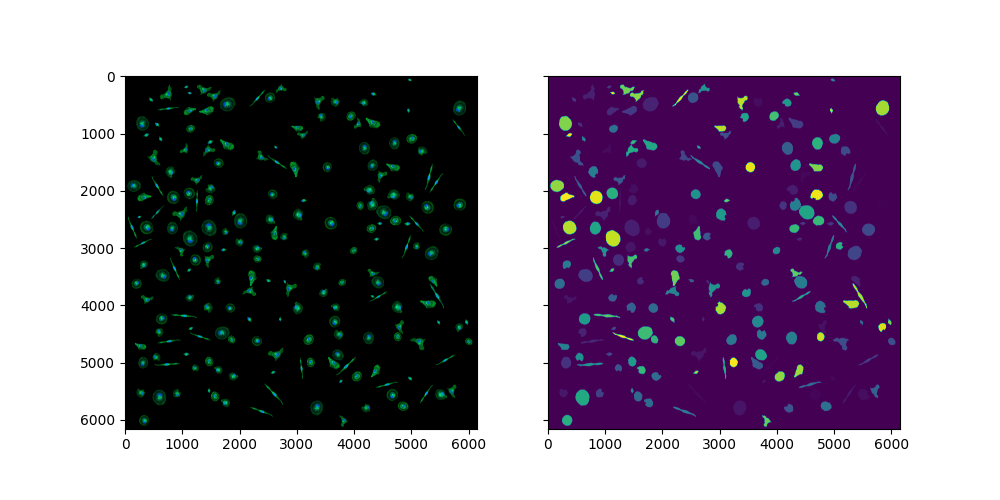

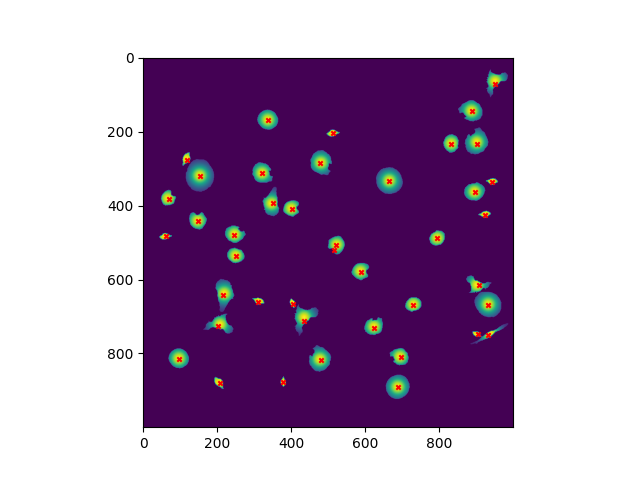

In [9]:
# render filled canvasses
fig, ax = plt.subplots(1,2, sharex=True, sharey=True, figsize=(10,5))
ax[0].imshow(mic_canvas[:,:])
ax[1].imshow(mask_canvas)

## uncomment to plot cell coordinates on canvas
#x_coords = []
#y_coords = []
#for key, item in coordinates.items():
#    x_coords.append(item[0])
#    y_coords.append(item[1])
#ax[0].scatter(x_coords, y_coords, color='red', s=10, marker='x')
#ax[1].scatter(x_coords, y_coords, color='red', s=10, marker='x')


plt.figure()
plt.imshow(ms_canvas[:,:,0])
x_coords = []
y_coords = []
for key, item in msi_coordinates.items():
    x_coords.append(item[0])
    y_coords.append(item[1])
plt.scatter(x_coords, y_coords, color='red', s=10, marker='x')

## Perform Pertubations

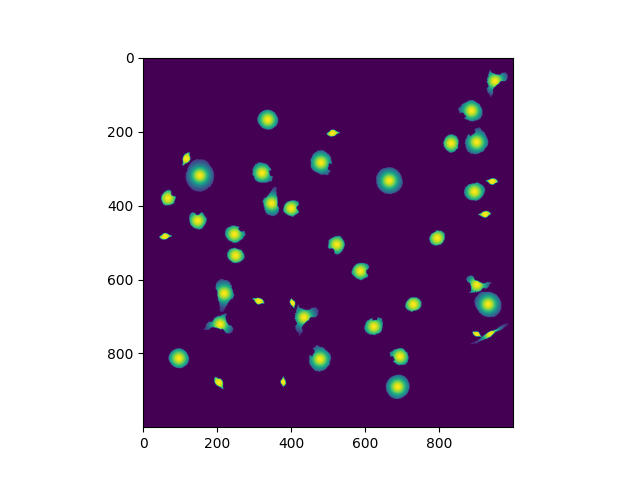

In [10]:
maldi_img = skimage.transform.rotate(skimage.transform.rescale(ms_canvas[:,:,0], scale), rotation)
maldi_canvas = np.zeros((len(maldi_img), len(maldi_img[0]), len(mass_list)))
for i in range(len(mass_list)):
    maldi_img = skimage.transform.rotate(skimage.transform.rescale(ms_canvas[:,:,i], scale), rotation)
    maldi_canvas[:,:,i] = maldi_img
noise = np.random.normal(loc=noise_loc, scale=noise_scale/ms_spacing, size=maldi_img.shape)
maldi_img += noise
maldi_img[maldi_img < 0] = 0
plt.figure()
plt.imshow(maldi_img)

## Validate Registration

### Perform registration

In [11]:
maldi_sitk = sitk.GetImageFromArray(maldi_img)
mic_sitk = sitk.GetImageFromArray(mic_canvas[:,:,1])
mask_sitk = sitk.GetImageFromArray(mask_canvas)
maldi_sitk = sitk.Cast(maldi_sitk, sitk.sitkFloat32)
mic_sitk = sitk.Cast(mic_sitk, sitk.sitkFloat32)
mask_sitk = sitk.Cast(mask_sitk, sitk.sitkFloat32)
maldi_sitk.SetSpacing([ms_spacing, ms_spacing])
mic_sitk.SetSpacing([mic_spacing, mic_spacing])
mask_sitk.SetSpacing([mic_spacing, mic_spacing])
scaling_factor = int(maldi_sitk.GetSpacing()[0] / mic_sitk.GetSpacing()[0])
moving_spacing = maldi_sitk.GetSpacing()[0] / scaling_factor
moving_size = (maldi_sitk.GetSize()[0] * scaling_factor, maldi_sitk.GetSize()[1] * scaling_factor)
moving_sitk = sitk.Resample(maldi_sitk, moving_size, interpolator=sitk.sitkNearestNeighbor, outputOrigin=(0.0, 0.0), outputSpacing=(moving_spacing, moving_spacing))
if manual_registration:
    point_acquisition_moving_mic = gui.RegistrationPointDataAquisition(mic_sitk, moving_sitk, moving_window_level=[1,0.5], fixed_window_level=[1,0.5])
    mic_sitk_points, moving_sitk_points = point_acquisition_moving_mic.get_points()
else:
    mic_sitk_points = [(0.26 * len(mic_canvas[0])*mic_spacing, 0.25 * len(mic_canvas)*mic_spacing),
                      (0.25 * len(mic_canvas[0])*mic_spacing, 0.75 * len(mic_canvas)*mic_spacing),
                      (0.76 * len(mic_canvas[0])*mic_spacing, 0.25 * len(mic_canvas)*mic_spacing),
                      (0.75 * len(mic_canvas[0])*mic_spacing, 0.75 * len(mic_canvas)*mic_spacing)]
    moving_sitk_points = [(0,0),
                         (0, len(maldi_img)*ms_spacing),
                         (len(maldi_img[0])*ms_spacing, 0),
                         (len(maldi_img[0])*ms_spacing, len(maldi_img)*ms_spacing)]
print(mic_sitk_points)
print(moving_sitk_points)

[(519.9285, 499.93125000000003), (499.93125000000003, 1499.79375), (1519.791, 499.93125000000003), (1499.79375, 1499.79375)]
[(0, 0), (0, 1000), (1000, 0), (1000, 1000)]


In [12]:
def normalize_to_uint8(img):
    arr = sitk.GetArrayFromImage(img)
    normalized_arr = arr / np.max(arr) * 255
    uint8_arr = np.clip(normalized_arr, 0, 255).astype(np.uint8)
    uint8_img = sitk.GetImageFromArray(uint8_arr)
    uint8_img.CopyInformation(img)
    return uint8_img

In [13]:
moving_sitk.GetSpacing()

(0.3333333333333333, 0.3333333333333333)

In [14]:
mic_image_points_flat = [c for p in mic_sitk_points for c in p]
moving_image_points_flat = [c for p in moving_sitk_points for c in p]
init_transform = sitk.Euler2DTransform(
    sitk.LandmarkBasedTransformInitializer(
        sitk.Euler2DTransform(), mic_image_points_flat, moving_image_points_flat
    )
)

similarity_transform = sitk.LandmarkBasedTransformInitializer(
    sitk.Similarity2DTransform(),
    mic_image_points_flat,
    moving_image_points_flat
)

initial_euler_transform = sitk.Euler2DTransform()
initial_euler_transform.SetCenter(init_transform.GetCenter())
initial_euler_transform.SetMatrix(init_transform.GetMatrix())
initial_euler_transform.SetTranslation(init_transform.GetTranslation())
print("manual initial transformation is: " + str(initial_euler_transform.GetParameters()))
initial_affine_transform = sitk.AffineTransform(mic_sitk.GetDimension())
composite_transform = sitk.CompositeTransform(mic_sitk.GetDimension())
composite_transform.AddTransform(similarity_transform)
composite_transform.AddTransform(initial_affine_transform)

manual initial transformation is: (-0.009999666686639172, -509.8611249999999, -499.86249999999995)


In [15]:
print("Microscope Image Spacing:", mic_sitk.GetSpacing())
print("Moving Image (Maldi) Spacing:", moving_sitk.GetSpacing())

# Print the acquired points
print("Microscope image landmark points:", mic_image_points_flat)
print("Moving image landmark points:", moving_image_points_flat)

# Check the transform parameters
print("Translation (after initialization):", similarity_transform.GetTranslation())
print("Rotation angle (after initialization):", similarity_transform.GetAngle())
print("Scale (after initialization):", similarity_transform.GetScale())

# Ensure spacing is appropriate
print("Effective scaling factor:", scaling_factor)
print("Moving image new size:", moving_size)

Microscope Image Spacing: (0.325, 0.325)
Moving Image (Maldi) Spacing: (0.3333333333333333, 0.3333333333333333)
Microscope image landmark points: [519.9285, 499.93125000000003, 499.93125000000003, 1499.79375, 1519.791, 499.93125000000003, 1499.79375, 1499.79375]
Moving image landmark points: [0, 0, 0, 1000, 1000, 0, 1000, 1000]
Translation (after initialization): (-509.8611249999999, -499.86249999999995)
Rotation angle (after initialization): -0.00999966668666521
Scale (after initialization): 1.0
Effective scaling factor: 3
Moving image new size: (3000, 3000)


In [16]:
test_sitk = sitk.Resample(moving_sitk,
                             mic_sitk,
                             similarity_transform,
                             sitk.sitkLinear,
                             0.0,
                             moving_sitk.GetPixelID()
                             )
composite_img = sitk.Compose([normalize_to_uint8(test_sitk), normalize_to_uint8(test_sitk), normalize_to_uint8(mic_sitk)])
sitk.Show(composite_img)

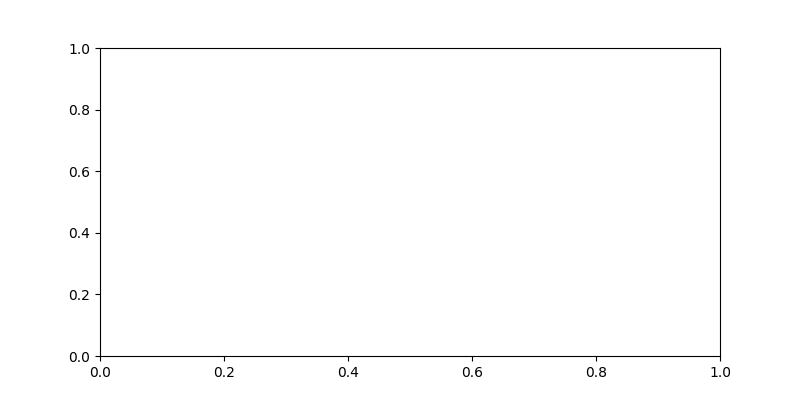

In [17]:
registration_method = sitk.ImageRegistrationMethod()
registration_method.SetMetricAsMattesMutualInformation(numberOfHistogramBins=50)
#registration_method.SetOptimizerAsLBFGSB(gradientConvergenceTolerance=1e-5,
#    numberOfIterations=100,
#    maximumNumberOfCorrections=5,
#    maximumNumberOfFunctionEvaluations=1000,
#    costFunctionConvergenceFactor=1e+6
#)
registration_method.SetOptimizerAsGradientDescent(
    learningRate = 1.0,
    numberOfIterations=2000,
    convergenceMinimumValue=1e-6,
    convergenceWindowSize=50
)
registration_method.AddCommand(sitk.sitkStartEvent, rgui.start_plot)
registration_method.AddCommand(sitk.sitkEndEvent, rgui.end_plot)
registration_method.AddCommand(sitk.sitkMultiResolutionIterationEvent, rgui.update_multires_iterations)
registration_method.AddCommand(sitk.sitkIterationEvent, lambda: rgui.plot_values(registration_method))
registration_method.SetShrinkFactorsPerLevel(shrinkFactors = [4,2,1])
registration_method.SetSmoothingSigmasPerLevel(smoothingSigmas=[2,1,0])
registration_method.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()
registration_method.SetInitialTransform(composite_transform, inPlace=False)
registration_method.SetInterpolator(sitk.sitkLinear)
registration_method.SetMetricSamplingStrategy(registration_method.RANDOM)
registration_method.SetMetricSamplingPercentage(0.1)
registration_method.SetOptimizerScalesFromPhysicalShift()
final_transform = registration_method.Execute(mic_sitk, moving_sitk)

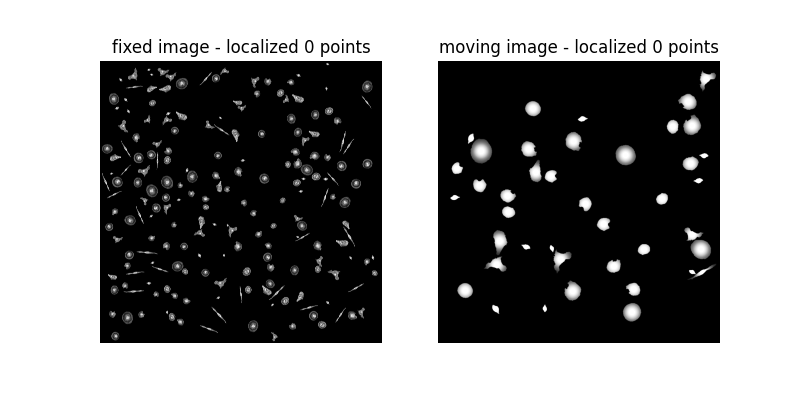

In [18]:
gui.RegistrationPointDataAquisition(
    mic_sitk,
    moving_sitk,
    figure_size=(8, 4),
    known_transformation=final_transform,
    moving_window_level=[1,0.5], 
    fixed_window_level=[1,0.5]
);


In [19]:
test_sitk = sitk.Resample(moving_sitk,
                             mic_sitk,
                             final_transform,
                             sitk.sitkLinear,
                             0.0,
                             moving_sitk.GetPixelID()
                             )
composite_img = sitk.Compose([normalize_to_uint8(test_sitk), normalize_to_uint8(test_sitk), normalize_to_uint8(mic_sitk)])
sitk.Show(composite_img)

### Evaluate results

In [20]:
interpret_registration_matrix(final_transform.GetNthTransform(0))

Transform 0:
Translation: (-509.8611249999999, -499.86249999999995) 
Rotation: [[ 0.99995    0.0099995]
 [-0.0099995  0.99995  ]] 
 Rotation in deg: -0.5729386976834844 
Scale: 1.0
Transform 1:
Affine Transform Matrix: (1.0000483904418578, -0.010225668851429707, 0.009398257628997136, 0.9992618487180085)
Translation: (19.458913101862404, -10.41907461934054)
Translation: (19.458913101862404, -10.41907461934054) 
Rotation: [[ 0.99995183 -0.00981488]
 [ 0.00981488  0.99995183]] 
 Rotation in deg: 0.5623599765860923 
Scale: [1.00027407 0.99913247] 
Shear: -0.009815033172865615


Mean error in µm: [-0.62887858 -1.67560612] +/- [0.29343075 0.37438222]
Mean error in µm: [0.62921129 1.67713531] +/- [0.29340232 0.37463647]


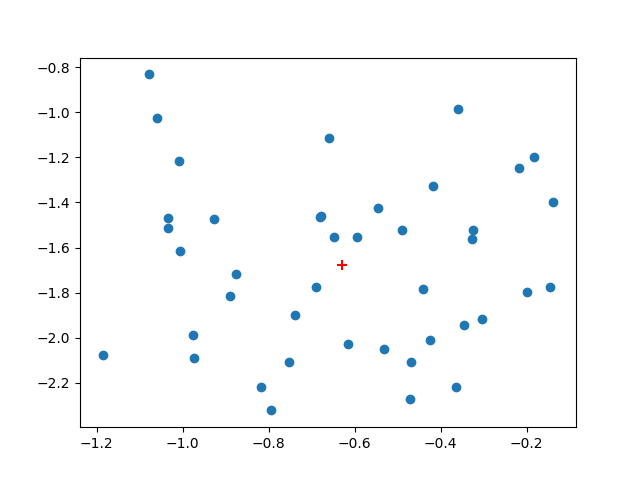

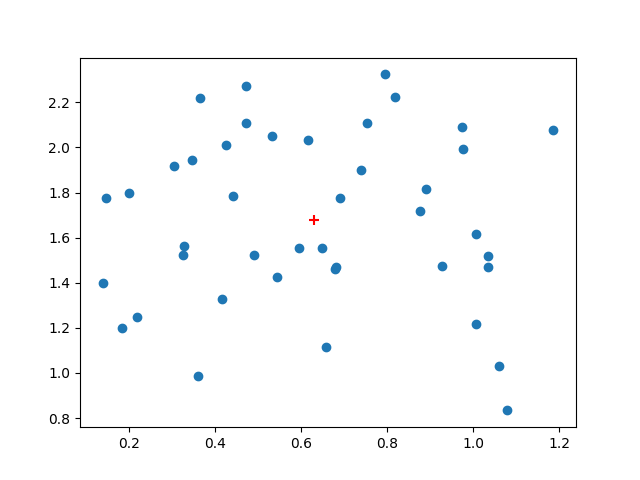

In [21]:
evaluate_registration(final_transform)

### Perfect registration

In [22]:
initial_transform = sitk.Euler2DTransform()
initial_transform.SetTranslation((-500,-500))
initial_transform.SetAngle(-rotation * (math.pi / 180))
affine_transform = sitk.AffineTransform(2)
scaling_factor = 1 / scale
scaling_matrix = [scaling_factor, 0,
                  0, scaling_factor]
affine_transform.SetMatrix(scaling_matrix)
perfect_registration = sitk.CompositeTransform(2)
perfect_registration.AddTransform(affine_transform)
perfect_registration.AddTransform(initial_transform)

In [23]:
interpret_registration_matrix(perfect_registration)

Transform 0:
Affine Transform Matrix: (1.0, 0.0, 0.0, 1.0)
Translation: (0.0, 0.0)
Translation: (0.0, 0.0) 
Rotation: [[1. 0.]
 [0. 1.]] 
 Rotation in deg: 0.0 
Scale: [1. 1.] 
Shear: 0.0
Transform 1:
Translation: (-500.0, -500.0) 
Rotation: [[ 1. -0.]
 [ 0.  1.]] 
 Rotation in deg: 0.0


Mean error in µm: [-0.03214286 -0.03571429] +/- [0.28159229 0.32358404]
Mean error in µm: [0.03214286 0.03571429] +/- [0.28159229 0.32358404]


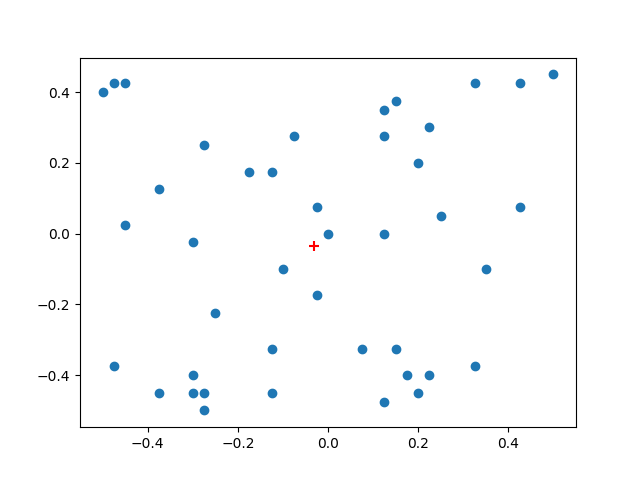

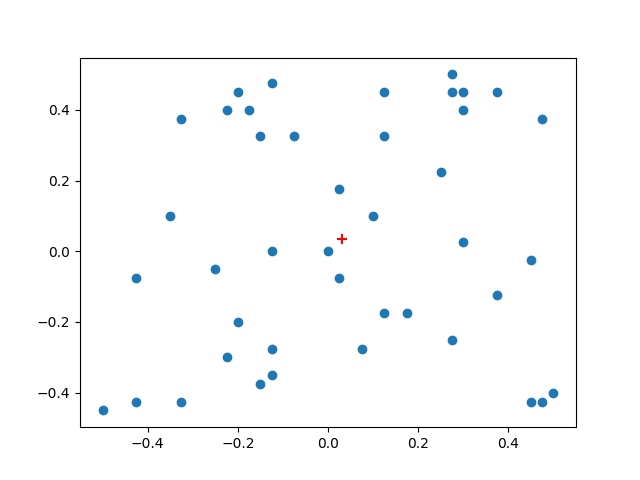

In [24]:
evaluate_registration(perfect_registration)

### Cut down images

In [28]:
mic_transformed = sitk.Resample(mic_sitk,
                             moving_sitk,
                             perfect_registration.GetInverse(),
                             sitk.sitkLinear,
                             0.0,
                             moving_sitk.GetPixelID()
                             )
mask_transformed = sitk.Resample(mask_sitk,
                             moving_sitk,
                             perfect_registration.GetInverse(),
                             sitk.sitkNearestNeighbor,
                             0.0,
                             moving_sitk.GetPixelID()
                             )
mic_cut = sitk.GetArrayFromImage(mic_transformed)
mask_cut = sitk.GetArrayFromImage(mask_transformed)

## Validate Segmentation

In [29]:
from cellpose import models
model = models.Cellpose(gpu=False, model_type='cyto2')
masks, flows, styles, diams = model.eval(mic_cut, diameter=120)

In [30]:
intersection = np.logical_and(mask_cut, masks).sum()
union = np.logical_or(mask_cut, masks).sum()
iou = intersection / union if union != 0 else 0
print(iou)

0.7640643844361141


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


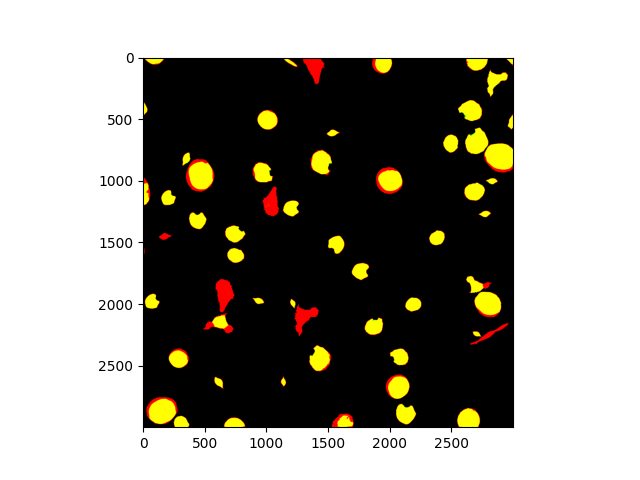

In [31]:
overlay_img = np.zeros((len(masks), len(masks[0]), 3))
overlay_img[:,:,0] = mask_cut
overlay_img[:,:,1] = masks
plt.figure()
plt.imshow(overlay_img)

## Validate Spectra Generation

In [32]:
ms_img = maldi_canvas[:,:,0]

In [33]:
ms_scale_factor = ms_spacing / moving_spacing

In [34]:
#mask_max = np.max(mask_cut)
#mask_min = np.min(mask_cut)
mask_max = np.max(masks)
mask_min = np.min(masks)
num_cells = int(mask_max - mask_min -1)
remove_ambiguous = True
# variant 1 scaling
cells = np.zeros((num_cells + 2, len(mass_list)))
print(cells.shape)
for i in trange(len(ms_img)):
    for j in range(len(ms_img[0])):
        #sub_region = mask_cut[int(i*ms_scale_factor):int((i+1)*ms_scale_factor), int(j*ms_scale_factor):int((j+1)*ms_scale_factor)].astype(np.int)
        sub_region = masks[int(i*ms_scale_factor):int((i+1)*ms_scale_factor), int(j*ms_scale_factor):int((j+1)*ms_scale_factor)]
        ids = set(sub_region[sub_region!=0].flatten())
        if len(ids) > 1:
            if remove_ambiguous == False:
                cell_area = np.count_nonzero(sub_region)
                for cell_id in ids:
                    area = np.count_nonzero(sub_region == cell_id) / cell_area#np.count_nonzero(sub_region)
                    cells[cell_id, :] += maldi_canvas[i,j,:] * area
        if len(ids) == 1:
            for cell_id in ids:
                cells[cell_id,:] += maldi_canvas[i,j,:]

(55, 2)


100%|█████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:05<00:00, 171.84it/s]


In [35]:
canvas_to_mask = {}
for key, value in msi_coordinates.items():
    x, y = value
    x_moving = int(x * ms_scale_factor)
    y_moving = int(y * ms_scale_factor)
    mask_id = 0
    subregion = masks[int(y*ms_scale_factor):int((y+1)*ms_scale_factor), int(x*ms_scale_factor):int((x+1)*ms_scale_factor)]
    ids = set(sub_region[sub_region!=0].flatten())
    if len(ids) > 1:
        print("more than one")
        counts = np.bincount(subregion)
        mask_id = int(np.argmax(counts))
    else:
        mask_id = int(np.max(subregion))
    if mask_id > 0:
        canvas_to_mask[key] = mask_id
        true_int = cell_intensities[key]
        meas_int = cells[mask_id][0]
        print(f"cell: ({key},{mask_id}), x/y: {x_moving}/{y_moving}, ground truth: {true_int}, measured: {meas_int}, difference: {true_int-meas_int}, relative difference: {(true_int-meas_int)/true_int:.2%}")
    elif mask_id == 0:
        canvas_to_mask[key] = mask_id
        true_int = cell_intensities[key]
        meas_int = 0
        print(f"cell: ({key},{mask_id}), x/y: {x_moving}/{y_moving}, ground truth: {true_int}, measured: {meas_int}, difference: {true_int-meas_int}, relative difference: {(true_int-meas_int)/true_int:.2%}")

cell: (2,42), x/y: 2712/2244, ground truth: 237.47480653340463, measured: 219.6736112732093, difference: 17.80119526019533, relative difference: 7.50%
cell: (5,18), x/y: 960/939, ground truth: 1677.9968244628615, measured: 1601.5997880082525, difference: 76.39703645460895, relative difference: 4.55%
cell: (16,27), x/y: 444/1323, ground truth: 1329.292207935376, measured: 1310.0373413836164, difference: 19.254866551759505, relative difference: 1.45%
cell: (19,7), x/y: 2667/432, ground truth: 1825.730320646947, measured: 1793.298993373772, difference: 32.43132727317493, relative difference: 1.78%
cell: (26,48), x/y: 1134/2628, ground truth: 242.69861650112676, measured: 215.9128993074073, difference: 26.785717193719478, relative difference: 11.04%
cell: (27,39), x/y: 1218/1998, ground truth: 226.4945646804734, measured: 211.46401534377512, difference: 15.030549336698272, relative difference: 6.64%
cell: (41,31), x/y: 753/1608, ground truth: 1213.5941217172817, measured: 1198.028847169689

C:\Users\schwenzj\AppData\Local\Temp\ipykernel_9752\1042150895.py:19: RuntimeWarning: divide by zero encountered in double_scalars
  print(f"cell: ({key},{mask_id}), x/y: {x_moving}/{y_moving}, ground truth: {true_int}, measured: {meas_int}, difference: {true_int-meas_int}, relative difference: {(true_int-meas_int)/true_int:.2%}")
